# Calibración estratificada y cobertura

**Pregunta:** ¿Cómo cambian beta y la reserva de frecuencias la recuperación MT sintética?

**Nivel 2 — Análisis aplicado**  
**Prerrequisitos:** nivel 1 y arreglos/logaritmos; 35 min.



## Objetivos

Pregunta: ¿Cómo cambian las estimaciones condicionales por capa y la cobertura bootstrap al reservar frecuencias y variar regularización en el modelo MT de espesores fijos?



## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8` `scipy==1.15.2` es requerido por el operador directo MT.



## Datos

Esta lección usa una calibración sintética con semilla, tres capas de espesores fijos de 250 m y 600 m, 24 frecuencias y 48 realizaciones bootstrap. Se reservan seis frecuencias antes del ajuste. El EDI medido Clear Lake cl061 aparece solo como registro QC separado y no aporta valores a estas inversas sintéticas.


## Método

Este artefacto es sintético: tierra 1D de dos capas, `[180,20] Ω·m`, espesor superior 450 m, 24 frecuencias, 48 realizaciones ruidosas independientes y 128 réplicas bootstrap por realización. La cobertura empírica es `C=N⁻¹Σ1[ρreal∈IC]`; la unidad independiente es la realización, no cada réplica. Compare cobertura con 95 % nominal y límites Wilson guardados, e inspeccione anchuras en Ω·m. El intervalo depende de espesor fijo, errores independientes gaussianos real/imaginario, cotas y regularización. No garantiza cobertura en campo; alta cobertura puede coexistir con sesgo o capas mal resueltas.

Los parámetros son log-resistividades: positivos por construcción y pasos iguales son cambios multiplicativos iguales. Residuos complejos usan sigma por componente real; ambas partes aportan al ajuste. Frecuencias no son muestras independientes de profundidad: kernels se solapan y un período no identifica una interfaz. Sensibilidad local y cobertura dependen de parametrización fija y no descartan equivalencia global.



Genere entradas con semilla antes de evaluar métodos directos, objetivo y sensibilidad. La máscara de frecuencia y el modelo de error se fijan antes del ajuste.

In [1]:
# Genere las observaciones con semilla y la máscara de frecuencias fijada que usa cada método.
import sys
from pathlib import Path
import numpy as np

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
import electromagnetics as em

f = np.logspace(-2, 2, 24)
h = np.array([250.0, 600.0])
truth = np.array([80.0, 8.0, 350.0])
z0 = em.impedance(truth, h, f)
sigma = np.maximum(np.abs(z0) * 0.035, 1e-12)
rng = np.random.default_rng(20261027)
zobs = z0 + sigma * (rng.normal(size=len(f)) + 1j * rng.normal(size=len(f)))
active = np.arange(len(f)) % 4 != 0
print("entrenamiento:", int(active.sum()), "retenido:", int((~active).sum()))


entrenamiento: 18 retenido: 6


Recalcule la respuesta compleja directa estratificada.

In [2]:
# Ejecute el método directo de tierra estratificada del producto.
z_target = em.impedance(truth, h, f)
print("períodos:", len(z_target), "finitos:", bool(np.isfinite(z_target).all()))


períodos: 24 finitos: True


Convierta impedancia compleja en resistividad aparente y fase.

In [3]:
# Convierta la respuesta modelada en las magnitudes observables usadas en la interpretación.
target_curves = em.curves(z_target, f)
print("Resistividad aparente mediana Ω·m:", float(np.median(target_curves["apparent"])))


Resistividad aparente mediana Ω·m: 37.915292342294244


Evalúe el objetivo complejo ponderado declarado.

In [4]:
# Evalúe el objetivo residual exacto en el modelo declarado.
objective = em.objective_residual(np.log(truth), h, f, zobs, sigma, 0.001, active)
print("Longitud del objetivo:", len(objective), "norma:", float(np.linalg.norm(objective)))


Longitud del objetivo: 38 norma: 0.9236433391734254


Inspeccione sensibilidad local condicionada a espesores fijos.

In [5]:
# Calcule el diagnóstico local de identificabilidad basado solo en los datos.
local_rank = em.identifiability(truth, h, f, sigma, active)
print("Rango efectivo:", local_rank["effective_rank"], "/", local_rank["parameter_count"])


Rango efectivo: 3 / 3


Confirme las versiones del entorno y el recibo de calibración antes de graficar los resultados por realización. Así se registra el entorno computacional y se verifica que la comparación use los 48 ajustes declarados, no un artefacto distinto.

In [6]:
from pathlib import Path
from importlib.metadata import version

print("Versiones del entorno:", {name: version(name) for name in ["numpy", "matplotlib", "scipy"]})
import numpy as np

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
# Inspeccione la procedencia de calibración sintética y las filas de realizaciones independientes.
import json
from pathlib import Path

cal = json.loads((root / "data/derived/v2/edi/calibration-two-layer.json").read_text(encoding="utf-8"))
print(
    cal["kind"],
    cal["calibration_model"],
    "Ω·m; espesor",
    cal["fixed_thickness_m"],
    "m; frecuencias",
    len(cal["frequencies_hz"]),
)
print(
    "realizaciones",
    cal['realizations'],
    "réplicas bootstrap por realización",
    cal["bootstrap_samples_per_realization"],
    "nominal",
    cal["confidence"],
    "cobertura",
    cal["coverage_per_layer"],
)


Versiones del entorno: {'numpy': '2.2.6', 'matplotlib': '3.10.8', 'scipy': '1.15.2'}
independent_seeded_conditional_bootstrap_coverage [180.0, 20.0] Ω·m; espesor [450.0] m; frecuencias 24
realizaciones 48 réplicas bootstrap por realización 128 nominal 0.95 cobertura [0.875, 1.0]


### Diagnóstico 2

Este diagnóstico recalcula la cobertura de intervalos por realización y su anchura mediana a partir de los ajustes de calibración declarados. Comparar la cobertura empírica con el objetivo nominal del 90 % muestra con qué frecuencia los intervalos condicionales contienen cada capa sintética conocida; la anchura registra la precisión por separado. Son cantidades distintas y ninguna constituye validación geológica.

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Recalcule la cobertura y las anchuras medianas de intervalo a partir de los 48 ajustes registrados.
import matplotlib.pyplot as plt

rows = cal["rows"]
truth = np.asarray(cal["calibration_model"], float)
cover = np.asarray([r["covered"] for r in rows], bool)
ci = np.asarray([r["interval_ohm_m"] for r in rows], float)
cov = cover.mean(0)
width = np.median(ci[:, 1, :] - ci[:, 0, :], axis=0)
print("cobertura", cov, "; anchura mediana del intervalo Ω·m", width)


cobertura [0.875 1.   ] ; anchura mediana del intervalo Ω·m [44.96804628  1.67527305]


### Graficar cobertura por realización

Las cantidades anteriores se recalculan con los 48 ajustes registrados, no se extraen del gráfico. Estos paneles comparan la cobertura empírica con la confianza solicitada y muestran el ancho condicional del intervalo para las capas superior e inferior.

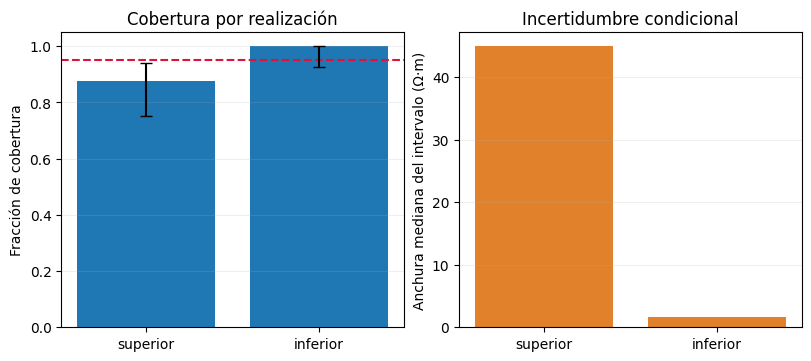

In [8]:
# Graficar cobertura por realización.
fig, ax = plt.subplots(1, 2, figsize=(8, 3.5), constrained_layout=True)
x = np.arange(2)
ax[0].bar(x, cov)
ax[0].axhline(cal["confidence"], ls="--", color="crimson")
ax[0].errorbar(
    x,
    cov,
    yerr=[
        np.maximum(0, cov - np.asarray(cal["coverage_wilson95_lower"])),
        np.maximum(0, np.asarray(cal["coverage_wilson95_upper"]) - cov),
    ],
    fmt="none",
    capsize=4,
    color="black",
)
ax[0].set(
    xticks=x,
    xticklabels=["superior", "inferior"],
    ylim=(0, 1.05),
    ylabel="Fracción de cobertura",
    title="Cobertura por realización",
)
ax[1].bar(x, width, color="#e1812c")
ax[1].set(
    xticks=x, xticklabels=["superior", "inferior"], ylabel="Anchura mediana del intervalo (Ω·m)", title="Incertidumbre condicional"
)
[a.grid(axis="y", alpha=0.2) for a in ax]
plt.show()


### Experimento controlado de regularización

Este sondeo 1D **sintético y reproducible** no es una interpretación de terreno. Genera una respuesta de tres capas con el operador directo del repositorio, agrega ruido complejo con semilla fija y ajusta solo períodos activos. Se reserva cada cuarta frecuencia y se usa solo para calcular el residuo de validación. El espesor es fijo: el experimento no evalúa recuperación de interfaces. La variación de beta muestra el compromiso entre ajuste y regularización con datos, semilla, modelo inicial y presupuesto idénticos.

Verdad sintética: resistividad en ohm m, espesor en m y frecuencia en Hz. Los datos reservados nunca se entregan al solver. La identificabilidad local es condicional y no demuestra unicidad.

In [9]:
# Genere un sondeo MT con semilla y resuelva tres intensidades de regularización.
import sys

sys.path.insert(0, str(root / "data-pipeline"))
import electromagnetics as em
import numpy as np

f = np.logspace(-2, 2, 24)
h = np.array([250.0, 600.0])
truth = np.array([80.0, 8.0, 350.0])
z0 = em.impedance(truth, h, f)
rng = np.random.default_rng(20261027)
sigma = np.maximum(abs(z0) * 0.035, 1e-12)
zobs = z0 + sigma * (rng.normal(size=len(f)) + 1j * rng.normal(size=len(f)))
active = np.arange(len(f)) % 4 != 0
betas = [0.0, 0.001, 0.1]
fits = {}


### Resolver las inversas regularizadas

La impedancia sintética, la incertidumbre y la máscara de frecuencias reservadas quedan fijadas arriba. Este paso llama la implementación de Levenberg–Marquardt del producto con tres valores beta e informa por separado WRMS activo y reservado.

In [10]:
# Resolver las inversas regularizadas.
for beta in betas:
    result = em.invert_mt(
        h,
        f,
        zobs,
        sigma,
        active=active,
        initial=[100.0, 30.0, 150.0],
        beta=beta,
        methods=("mt-lm",),
        max_nfev=120,
        record_every=20,
    )["mt-lm"]
    fits[beta] = result
    metrics = result["metrics"]
    print(
        f"beta={beta:g}; modelo={np.round(result['model'], 2)} Ω·m; "
        f"WRMS de ajuste={metrics['active_component_wrms']:.3f}; "
        f"WRMS retenido={metrics['withheld_component_wrms']:.3f}"
    )


beta=0; modelo=[ 77.05   7.9  326.58] Ω·m; WRMS de ajuste=0.855; WRMS retenido=1.010
beta=0.001; modelo=[ 77.03   7.9  326.49] Ω·m; WRMS de ajuste=0.855; WRMS retenido=1.011
beta=0.1; modelo=[ 74.87   7.97 318.04] Ω·m; WRMS de ajuste=0.861; WRMS retenido=1.029


### Comparar respuestas ajustadas y retenidas entre valores de beta

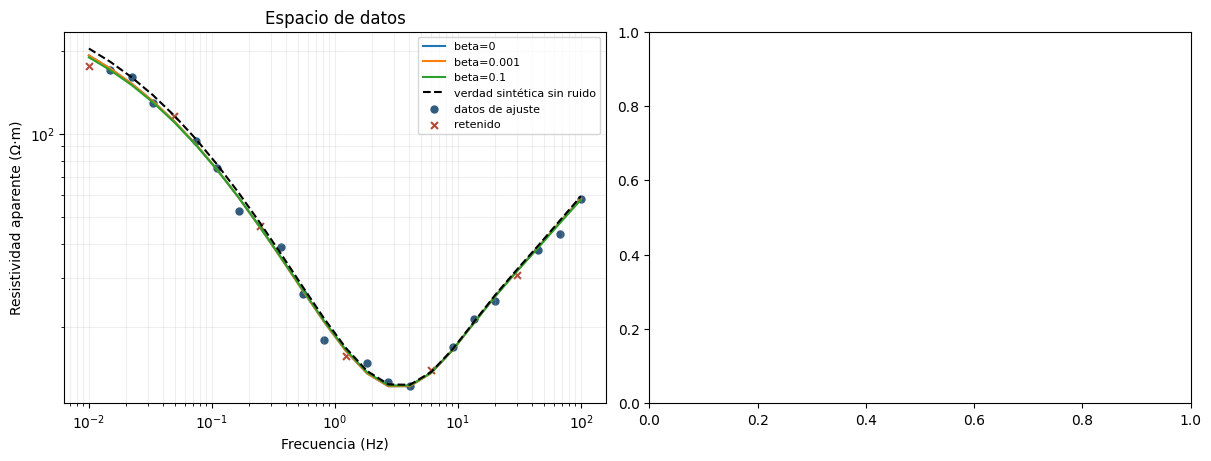

In [11]:
# Compare las predicciones resueltas en el espacio de datos y los modelos con espesores fijos.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for beta, result in fits.items():
    ax[0].loglog(f, result["predicted"]["apparent"], label=f"beta={beta:g}")
truth_apparent = abs(z0) ** 2 / (em.MU * 2 * np.pi * f)
ax[0].loglog(f, truth_apparent, "k--", label="verdad sintética sin ruido")
for mask, marker, color, label in (
    (active, "o", "#315b7d", "datos de ajuste"),
    (~active, "x", "#b34a36", "retenido"),
):
    observed_apparent = abs(zobs[mask]) ** 2 / (em.MU * 2 * np.pi * f[mask])
    ax[0].scatter(f[mask], observed_apparent, s=25, marker=marker, color=color, label=label)
ax[0].set(xlabel="Frecuencia (Hz)", ylabel="Resistividad aparente (Ω·m)", title="Espacio de datos")
ax[0].grid(True, which="both", alpha=0.2)
ax[0].legend(fontsize=8)
plt.show()


### Comparar los modelos de capas recuperados

El primer panel compara resistividad aparente predicha con observaciones ruidosas de ajuste y reserva. Este panel muestra las tres soluciones frente al modelo sintético conocido con espesores fijos, para hacer visibles los intercambios de resistividad. Las curvas evalúan solo esta banda de frecuencias y geometría fija; no demuestran recuperación de profundidades de interfaz ni unicidad.


In [12]:
# Comparar los modelos de capas recuperados.
layer_ids = np.arange(3)
bar_width = 0.24
for position, beta in enumerate(betas):
    offset = (position - 1) * bar_width
    ax[1].bar(layer_ids + offset, fits[beta]['model'], bar_width, label=f"beta={beta:g}")
ax[1].scatter(layer_ids, truth, marker="D", color="black", label="verdad sintética", zorder=3)
ax[1].set(
    xticks=layer_ids,
    xticklabels=["Capa 1", "Capa 2", "Capa 3"],
    ylabel="Resistividad (Ω·m)",
    title="Espacio del modelo; espesor fijo",
)
ax[1].grid(axis="y", alpha=0.2)
ax[1].legend(fontsize=8)
fig.suptitle("Regularización MT · 1D sintética · mínimos cuadrados acotados en CPU")
plt.show()


Compare por separado frecuencias ajustadas y retenidas; luego observe cómo beta cambia el modelo con espesores fijos. Son resultados sintéticos controlados; las filas retenidas evalúan predicción dentro del mismo generador, no unicidad geológica.

El registro medido Clear Lake cl061 se conserva únicamente como evidencia QC. El tensor comprometido y sus varianzas marginales son entradas de la compuerta 1D necesaria y del diagnóstico del tensor de fase. La compuerta normaliza desviaciones diagonales y de antisimetría en todas las frecuencias disponibles. Si falla, no significa que el EDI carezca de valor; significa que no es elegible para esta inversa estratificada según la regla declarada. No se deben ajustar ventanas hasta forzar el aprobado ni pasar cl061 al ajuste sintético. Se preservan estado medido, grilla original, tipper incompleto y veredicto negativo.
La recurrencia directa MT utiliza impedancia compleja en capas finitas. El ajuste en log-resistividad mantiene positividad. El experimento separa frecuencias de validación antes de formar la máscara; todos los métodos usan mismas observaciones activas, modelo inicial, espesores fijos, límites e incertidumbre. Compare residuales complejos activos y retenidos, no solo curvas de resistividad aparente. El barrido de beta cambia el peso de suavidad y puede intercambiar ajuste por simplicidad del modelo. Un residual retenido que empeora mientras mejora entrenamiento muestra una consecuencia predictiva. Como el espesor permanece fijado, las interfaces son supuestos de entrada, no parámetros recuperados.
Una comparación de métodos solo es válida si las implementaciones resuelven el mismo objetivo. Aquí se apilan partes real e imaginaria de impedancia, se dividen por incertidumbre y se penaliza la rugosidad adyacente en log-resistividad. Se usan observaciones sintéticas únicas y una reserva congelada. El rango local del Jacobiano condiciona sensibilidad al espesor fijo y banda elegida; no demuestra unicidad global ni incluye dimensionalidad, static shift o errores correlacionados. La pérdida de rango en banda baja advierte que los períodos disponibles no separan todos los parámetros. La verdad sintética cuantifica este control y nunca debe renombrarse como precisión de campo.

## Resultados

En 48 ajustes con semilla, la cobertura de intervalos al 95 % es 0.875 para la capa superior y 1.000 para la inferior; las anchuras medianas son 44.97 y 1.675 Ω·m. Al subir beta de 0 a 0.1, la tercera capa cambia de 326.58 a 318.04 Ω·m y el WRMS reservado de 1.010 a 1.029.
### Contrato de calibración bootstrap



**Respuesta:** En 48 ajustes con semilla, la cobertura de intervalos al 95 % es 0.875 para la capa superior y 1.000 para la inferior; las anchuras medianas son 44.97 y 1.675 Ω·m. Al subir beta de 0 a 0.1, la tercera capa cambia de 326.58 a 318.04 Ω·m y el WRMS reservado de 1.010 a 1.029.

Las 48 realizaciones usan espesor fijo de 450 m y el mismo modelo sintético; cobertura depende de esas elecciones.


## Resumen

La capa inferior alcanza la cobertura nominal en esta calibración y la superior queda por debajo; mayor regularización empeora levemente el WRMS reservado. Espesores fijos, una familia sintética y 48 realizaciones limitan el resultado a calibración condicional, no incertidumbre de campo.



## Referencias

- [https://github.com/MTgeophysics/mtpy-v2](https://github.com/MTgeophysics/mtpy-v2)
- [https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california)